In [1]:
# Import Packages

import numpy as np
from scipy.integrate import solve_ivp

In [2]:
# Config

HOURS = None            # Simulated time (h)
SEED = 0                # RNG seed (None = random)
RECORD_EVERY = 360      # Sampling interval (s), multiple of 3
PRINT_EVERY = 36000     # Progress message interval (s), 0 = off
NOISE = False            # Measurement noise on/off
DATASET = "ramp_dist"    # "spaced", "clean" or "ramp_dist"

# Initial set points SETPT(1..20). Cascaded set points (1, 2, 3, 4, 6, 9, 10, 16)
# are adjusted by outer loops during the run; 12 is not used.
SETPOINTS = {
    1:  3664.0,     # D feed flow (kg/h)
    2:  4509.3,     # E feed flow (kg/h)
    3:  0.25052,    # A feed flow (kscmh)
    4:  9.3477,     # A and C feed flow (kscmh)
    5:  26.902,     # Recycle flow (kscmh)
    6:  0.33712,    # Purge rate (kscmh)
    7:  50.0,       # Separator level (%)
    8:  50.0,       # Stripper level (%)
    9:  230.31,     # Stripper steam flow (kg/h)
    10: 94.599,     # Reactor CW outlet temperature (C)
    11: 22.949,     # Stripper underflow (m3/h)
    12: 2633.7,     # Separator pressure (kPa)
    13: 32.188,     # Reactor feed A (mol%)
    14: 6.8820,     # Reactor feed D (mol%)
    15: 18.776,     # Reactor feed E (mol%)
    16: 65.731,     # Stripper temperature (C)
    17: 75.0,       # Reactor level (%)
    18: 120.40,     # Reactor temperature (C)
    19: 13.823,     # Purge B (mol%)
    20: 0.83570,    # Product E (mol%)
}

# Set point changes: (SETPT, t (h), new value)
SP_TESTS = {            # SETPT: (largest change, hold time (h))
    5:  (1.0,  1.5),    # Recycle flow (kscmh)
    7:  (8.0,  2.0),    # Separator level (%)
    8:  (8.0,  1.0),    # Stripper level (%)
    18: (1.5,  1.0),    # Reactor temperature (C)
    11: (0.8,  2.0),    # Stripper underflow (m3/h)
    17: (2.5,  2.0),    # Reactor level (%)
    13: (1.2,  2.5),    # Reactor feed A (mol%)
    14: (0.4,  2.5),    # Reactor feed D (mol%)
    15: (1.5,  2.5),    # Reactor feed E (mol%)
    19: (2.0,  2.5),    # Purge B (mol%)
    20: (0.12, 2.5),    # Product E (mol%)
}
SP_STEPS = [0.35, -0.7, 1.0, -0.35, 0.7, -1.0]   # Training changes, fractions of the largest change
TEST_STEP = 0.5                                  # Test changes, fraction of the largest change
T_START, T_TEST_GAP, T_END = 10.0, 5.0, 5.0      # Nominal stretches (h): start, before the test part, end
GAP_MAX = 0.5                                    # Largest random extra nominal time after each excursion (h)
SPACING = 2.0                                    # Scales hold times and nominal stretches between changes
SCHEDULE_SEED = 1                                # RNG seed for the order, signs and gaps of the changes

rng_sched = np.random.default_rng(SCHEDULE_SEED)
SETPOINT_SCHEDULE = []


def add_excursion(k, f, t_c):
    dmax, hold = SP_TESTS[k]
    hold *= SPACING
    SETPOINT_SCHEDULE.extend([(k, t_c, round(float(SETPOINTS[k] + f * dmax), 6)),
                              (k, round(t_c + hold, 2), SETPOINTS[k])])
    gap = SPACING * 0.05 * rng_sched.integers(0, int(GAP_MAX / 0.05) + 1)
    return round(float(t_c + 2 * hold + gap), 2)


train = [(k, f) for k in SP_TESTS for f in SP_STEPS]
t_c = T_START
for i in rng_sched.permutation(len(train)):
    t_c = add_excursion(*train[i], t_c)

T_TEST = t_c + T_TEST_GAP
t_c = T_TEST
for k in rng_sched.permutation(list(SP_TESTS)):
    t_c = add_excursion(int(k), TEST_STEP * int(rng_sched.choice([-1, 1])), t_c)

if HOURS is None:
    HOURS = t_c + T_END

# Stochastic disturbances: AR(1) process for each of the 12 disturbance signals
DIST_STD = [
    0.001,      # Feed 4 A fraction
    0.00015,    # Feed 4 B fraction
    1.0,        # D feed temp (C)
    1.0,        # C feed temp (C)
    0.5,        # Reactor CW inlet temp (C)
    0.2,        # Condenser CW inlet temp (C)
    0.005,      # Reaction 1 factor
    0.005,      # Reaction 2 factor
    0.02,       # Stripper steam UA factor
    0.01,       # Reactor heat transfer factor
    0.01,       # Condenser heat transfer factor
    0.01,       # Reactor-separator flow factor
]
DIST_TAU = [6.0, 6.0, 6.0, 6.0, 3.0, 3.0, 10.0, 10.0, 6.0, 3.0, 3.0, 3.0]

DIST_SCHEDULE = []       # disturbance ramps

# Clean: 4 set points, no disturbances
if DATASET in ["clean", "ramp_dist"]:
    SP_LARGEST = {           # SETPT: largest change
        11: 0.8,             # Stripper underflow = production rate (m3/h), nominal 22.949
        18: 1.5,             # Reactor temperature (C), nominal 120.4
        19: 2.0,             # Purge B (mol%), nominal 13.823
        20: 0.12,            # Product E (mol%), nominal 0.8357
    }
    STEP_FRACTIONS = [0.25, -0.25, 0.5, -0.5, 1.0, -1.0]   # training steps, fractions of the largest change
    TEST_FRACTION = 0.75                                  # test steps, fraction of the largest change
    HOLD = 10.0              # hours at the new set point
    NOMINAL = 10.0           # hours back at nominal after each step
    T_START, T_END = 10.0, 5.0   # nominal hours at the start and the end of the run
    DIST_STD = [0.0] * 12    # no stochastic disturbances

if DATASET == "clean":
    rng_sched = np.random.default_rng(SCHEDULE_SEED)
    SETPOINT_SCHEDULE = []

    # Training part
    train_steps = []
    for k in SP_LARGEST:
        for frac in STEP_FRACTIONS:
            train_steps.append((k, frac))

    t_c = T_START
    for i in rng_sched.permutation(len(train_steps)):
        k, frac = train_steps[i]
        SETPOINT_SCHEDULE.append((k, t_c, round(SETPOINTS[k] + frac * SP_LARGEST[k], 6)))
        SETPOINT_SCHEDULE.append((k, t_c + HOLD, SETPOINTS[k]))
        t_c = t_c + HOLD + NOMINAL

    # Test part
    T_TEST = t_c
    for k in rng_sched.permutation(list(SP_LARGEST)):
        k = int(k)
        sign = int(rng_sched.choice([-1, 1]))
        SETPOINT_SCHEDULE.append((k, t_c, round(SETPOINTS[k] + sign * TEST_FRACTION * SP_LARGEST[k], 6)))
        SETPOINT_SCHEDULE.append((k, t_c + HOLD, SETPOINTS[k]))
        t_c = t_c + HOLD + NOMINAL

    HOURS = t_c + T_END

# Ramped disturbances: set point steps as in "clean", disturbances ramped between operating points
if DATASET == "ramp_dist":
    DIST_LARGEST = [         # largest offset from nominal
        0.005,      # Feed 4 A fraction (nominal 0.485)
        0.0005,     # Feed 4 B fraction (nominal 0.005)
        3.0,        # D feed temp (C)
        3.0,        # C feed temp (C)
        1.5,        # Reactor CW inlet temp (C)
        1.0,        # Condenser CW inlet temp (C)
        0.015,      # Reaction 1 factor
        0.015,      # Reaction 2 factor
        0.05,       # Stripper steam UA factor
        0.03,       # Reactor heat transfer factor
        0.03,       # Condenser heat transfer factor
        0.03,       # Reactor-separator flow factor
    ]
    RAMP = 5.0               # hours to ramp the disturbances to their new values
    SETTLE = 5.0             # hours after the ramp before the first set point step
    MAX_STEPS = 3            # most set point steps at one operating point
    TRAIN_CYCLES = 2         # cycles through the 12 disturbances in the training part
    TEST_POINTS = 3          # operating points in the test part

    rng_sched = np.random.default_rng(SCHEDULE_SEED)
    SETPOINT_SCHEDULE = []

    # Disturbance groups
    train_groups, test_groups = [], []
    for cycle in range(TRAIN_CYCLES + 1):
        order = [int(i) + 1 for i in rng_sched.permutation(12)]
        while order:
            size = int(rng_sched.integers(1, 3))
            if cycle < TRAIN_CYCLES:
                train_groups.append(order[:size])
            else:
                test_groups.append(order[:size])
            order = order[size:]
    test_groups = test_groups[:TEST_POINTS]

    # Number of set point steps per operating point
    def steps_per_point(n_steps, n_points, max_steps):
        counts = [0] * n_points
        for _ in range(n_steps):
            p = int(rng_sched.integers(n_points))
            while counts[p] == max_steps:
                p = int(rng_sched.integers(n_points))
            counts[p] += 1
        return counts

    # One operating point: disturbance ramps, then the set point steps
    def add_operating_point(group, steps, moved, t_c):
        for i in moved:
            if i not in group:
                DIST_SCHEDULE.append((i, t_c, t_c + RAMP, 0.0))
        for i in group:
            offset = int(rng_sched.choice([-1, 1])) * rng_sched.uniform(0.5, 1.0) * DIST_LARGEST[i - 1]
            DIST_SCHEDULE.append((i, t_c, t_c + RAMP, round(float(offset), 6)))
        t_c = t_c + RAMP + SETTLE
        if not steps:
            t_c = t_c + HOLD
        for k, frac in steps:
            SETPOINT_SCHEDULE.append((k, t_c, round(SETPOINTS[k] + frac * SP_LARGEST[k], 6)))
            SETPOINT_SCHEDULE.append((k, t_c + HOLD, SETPOINTS[k]))
            t_c = t_c + HOLD + NOMINAL
        return t_c

    # Training part
    train_steps = []
    for k in SP_LARGEST:
        for frac in STEP_FRACTIONS:
            train_steps.append((k, frac))
    train_steps = [train_steps[i] for i in rng_sched.permutation(len(train_steps))]
    counts = steps_per_point(len(train_steps), len(train_groups), MAX_STEPS)

    t_c = T_START
    moved = []
    for group, n in zip(train_groups, counts):
        t_c = add_operating_point(group, train_steps[:n], moved, t_c)
        train_steps = train_steps[n:]
        moved = group

    # Test part
    T_TEST = t_c
    test_steps = []
    for k in rng_sched.permutation(list(SP_LARGEST)):
        test_steps.append((int(k), int(rng_sched.choice([-1, 1])) * TEST_FRACTION))
    counts = steps_per_point(len(test_steps), len(test_groups), 2)
    for group, n in zip(test_groups, counts):
        t_c = add_operating_point(group, test_steps[:n], moved, t_c)
        test_steps = test_steps[n:]
        moved = group

    HOURS = t_c + T_END

CONFIG = {
    "hours": HOURS,
    "seed": SEED,
    "record_every": RECORD_EVERY,
    "print_every": PRINT_EVERY,
    "noise": NOISE,
    "setpoint_schedule": SETPOINT_SCHEDULE,
    "t_test": T_TEST,
    "spacing": SPACING,
    "dist_std": DIST_STD,
    "dist_tau": DIST_TAU,
    "dist_schedule": DIST_SCHEDULE,
    "dataset": DATASET,
    "setpoints": SETPOINTS,
}

# Define Constants

SP_CHANGEABLE = {5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20}   # set points that may be changed

XMW = np.array([2.0, 25.4, 28.0, 32.0, 46.0, 48.0, 62.0, 76.0])                                         # Molecular weights (g/mol)
AVP = np.array([0, 0, 0, 15.92, 16.35, 16.35, 16.43, 17.21])                                            # Antoine coefficients for vapor pressure
BVP = np.array([0, 0, 0, -1444.0, -2114.0, -2114.0, -2748.0, -3318.0])                                  # Antoine coefficients for vapor pressure
CVP = np.array([0, 0, 0, 259.0, 265.5, 265.5, 232.9, 249.6])                                            # Antoine coefficients for vapor pressure
AD = np.array([1, 1, 1, 23.3, 33.9, 32.8, 49.9, 50.5])                                                  # Liquid density coefficients
BD = np.array([0, 0, 0, -0.0700, -0.0957, -0.0995, -0.0191, -0.0541])                                   # Liquid density coefficients
CD = np.array([0, 0, 0, -0.0002, -0.000152, -0.000233, -0.000425, -0.000150])                           # Liquid density coefficients
AH = np.array([1e-6, 1e-6, 1e-6, 0.960e-6, 0.573e-6, 0.652e-6, 0.515e-6, 0.471e-6])                     # Heat capacity coefficients (liquid)
BH = np.array([0, 0, 0, 8.70e-9, 2.41e-9, 2.18e-9, 5.65e-10, 8.70e-10])                                 # Heat capacity coefficients (liquid)
CH = np.array([0, 0, 0, 4.81e-11, 1.82e-11, 1.94e-11, 3.82e-12, 2.62e-12])                              # Heat capacity coefficients (liquid)
AV = np.array([1e-6, 1e-6, 1e-6, 86.7e-6, 160e-6, 160e-6, 225e-6, 209e-6])                              # Heat of vaporisation
AG = np.array([3.411e-6, 0.3799e-6, 0.2491e-6, 0.3567e-6, 0.3463e-6, 0.3930e-6, 0.170e-6, 0.150e-6])    # Heat capacity coefficients (gas)
BG = np.array([7.18e-10, 1.08e-9, 1.36e-11, 8.51e-10, 8.96e-10, 1.02e-9, 0, 0])                         # Heat capacity coefficients (gas)
CG = np.array([6.0e-13, -3.98e-13, -3.93e-14, -3.12e-13, -3.27e-13, -3.12e-13, 0, 0])                   # Heat capacity coefficients (gas)

VRNG = np.array([400, 400, 100, 1500, 0, 0, 1500, 1000, 0.03, 1000, 1200, 0.0])  # Valve flow ranges
VTAU = np.array([8, 8, 6, 9, 7, 5, 5, 5, 120, 5, 5, 5]) / 3600.0                 # Valve time constants (h)
VTR, VTS, VTC, VTV = 1300.0, 3500.0, 156.5, 5000.0                               # Vessel volumes
HTR = np.array([0.06899381054, 0.05])                                            # Heat of reaction (kcal/mol) for reactions 1 and 2
HWR, HWS = 7060.0, 11138.0
CPFLMX, CPPRMX = 280275.0, 1.3
RG = 998.9

# Fixed feed compositions (streams 1-3); stream 4 is disturbed
X_FEED = {1: [0, 0.0001, 0, 0.9999, 0, 0, 0, 0],      # D feed
          2: [0, 0, 0, 0, 0.9999, 0.0001, 0, 0],      # E feed
          3: [0.9999, 0.0001, 0, 0, 0, 0, 0, 0]}      # A feed

# Measurement noise standard deviations, XMEAS(1..41)
XNS = np.array([0.0012, 18.0, 22.0, 0.05, 0.2, 0.21, 0.3, 0.5, 0.01, 0.0017, 0.01, 1.0, 0.3, 0.125, 
                1.0, 0.3, 0.115, 0.01, 1.15, 0.2, 0.01, 0.01, 0.25, 0.1, 0.25, 0.1, 0.25, 0.025, 
                0.25, 0.1, 0.25, 0.1, 0.25, 0.025, 0.05, 0.05, 0.01, 0.01, 0.01, 0.5, 0.5])

# Nominal values of the 12 disturbance signals
DIST_MEAN = np.array([0.485, 0.005, 45, 45, 35, 40, 1.0, 1.0, 0, 0, 0, 0])

# Initial states
Y0 = np.array([
    10.40491389, 4.363996017, 7.570059737, 0.4230042431, 24.15513437, 2.942597645,
    154.3770655, 159.1865960, 2.808522723, 63.75581199, 26.74026066, 46.38532432,
    0.2464521543, 15.20484404, 1.852266172, 52.44639459, 41.20394008, 0.5699317760,
    0.4306056376, 7.9906200783e-03, 0.9056036089, 1.6054258216e-02, 0.7509759687,
    8.8582855955e-02, 48.27726193, 39.38459028, 0.3755297257, 107.7562698, 29.77250546,
    88.32481135, 23.03929507, 62.85848794, 5.546318688, 11.92244772, 5.555448243,
    0.9218489762, 94.59927549, 77.29698353, 63.05263039, 53.97970677, 24.64355755,
    61.30192144, 22.21000000, 40.06374673, 38.10034370, 46.53415582, 47.44573456,
    41.10581288, 18.11349055, 50.00000000])


In [3]:
# Auxiliary Functions

# Thermodynamic functions

def enthalpy(x, t, ity):
    # x = molar composition, t = temperature, ity = phase (0=liq, 1=gas, 2=gas with pressure correction)
    if ity == 0:
        hi = 1.8 * t * (AH + BH * t / 2 + CH * t**2 / 3)
    else:
        hi = 1.8 * t * (AG + BG * t / 2 + CG * t**2 / 3) + AV
    h = np.sum(x * XMW * hi)
    if ity == 2:
        h -= 3.57696e-6 * (t + 273.15)
    return h


def d_enthalpy(x, t, ity):
    # x = molar composition, t = temperature, ity = phase (0=liq, 1=gas, 2=gas with pressure correction)
    if ity == 0:
        dhi = 1.8 * (AH + BH * t + CH * t**2)
    else:
        dhi = 1.8 * (AG + BG * t + CG * t**2)
    dh = np.sum(x * XMW * dhi)
    if ity == 2:
        dh -= 3.57696e-6
    return dh

# Newton iteration for temperature from specific enthalpy
def temperature(x, h, ity, t_guess):
    # x = molar composition, h = specific enthalpy, ity = phase (0=liq, 1=gas, 2=gas with pressure correction)
    t = t_guess
    for _ in range(100):
        dt = -(enthalpy(x, t, ity) - h) / d_enthalpy(x, t, ity)
        t += dt
        if abs(dt) < 1e-12:
            return t
    return t_guess


def density(x, t):
    # x = molar composition, t = temperature
    return 1.0 / np.sum(x * XMW / (AD + BD * t + CD * t**2))


# TEP Plant Dynamic Model

class TEPlant:
    def __init__(self, seed=None, dist_std=DIST_STD, dist_tau=DIST_TAU):
        self.rng = np.random.default_rng(seed)
        self.vcv = Y0[38:50].copy()               # valve commands
        self.t_guess = np.array([120.0, 80.0, 65.0, 100.0])  # reactor, sep, stripper, vapour
        self.dist_std = np.asarray(dist_std, dtype=float)
        self.dist_tau = np.asarray(dist_tau, dtype=float)
        self.dist = DIST_MEAN.copy()              # disturbance signals, start at nominal
        self.dist_dev = np.zeros(12)              # AR(1) part of the disturbance signals

    # Disturbances

    # AR(1) update of the disturbance signals
    def update_disturbances(self, dt, mean=DIST_MEAN):
        phi = np.exp(-dt / self.dist_tau)
        e = self.rng.standard_normal(12)
        self.dist_dev = phi * self.dist_dev + self.dist_std * np.sqrt(1 - phi**2) * e
        self.dist = mean + self.dist_dev

    # Valves follow the controller commands
    def update_valves(self, xmv):
        self.vcv = np.clip(xmv, 0, 100)

    # Dynamic Model
    def model(self, t, y):
        dist = self.dist

        # Disturbed feed (stream 4) and temperatures
        x4 = np.zeros(8)
        x4[0] = dist[0]
        x4[1] = dist[1]
        x4[2] = 1 - x4[0] - x4[1]
        t_feed = {1: dist[2], 2: 45.0, 3: 45.0, 4: dist[3]}
        tcwr = dist[4]
        tcws = dist[5]
        r1f, r2f = dist[6], dist[7]

        # States
        uclr = np.r_[0, 0, 0, y[3:8]]
        ucls = np.r_[0, 0, 0, y[12:17]]
        ucvr, ucvs = y[0:3], y[9:12]
        uclc, ucvv = y[18:26], y[27:35]
        etr, ets, etc, etv = y[8], y[17], y[26], y[35]
        twr, tws = y[36], y[37]
        vpos = y[38:50]

        xlr, xls = uclr / uclr.sum(), ucls / ucls.sum()
        xlc, xvv = uclc / uclc.sum(), ucvv / ucvv.sum()

        # Temperatures from energy holdups
        tcr = temperature(xlr, etr / uclr.sum(), 0, self.t_guess[0])
        tcs = temperature(xls, ets / ucls.sum(), 0, self.t_guess[1])
        tcc = temperature(xlc, etc / uclc.sum(), 0, self.t_guess[2])
        tcv = temperature(xvv, etv / ucvv.sum(), 2, self.t_guess[3])
        self.t_guess[:] = tcr, tcs, tcc, tcv
        tkr, tks, tkv = tcr + 273.15, tcs + 273.15, tcv + 273.15

        # Volumes and pressures
        dls, dlc = density(xls, tcs), density(xlc, tcc)
        vlr = uclr.sum() / density(xlr, tcr)
        vls = ucls.sum() / dls
        vlc = uclc.sum() / dlc
        vvr, vvs = VTR - vlr, VTS - vls

        ppr, pps = np.zeros(8), np.zeros(8)
        ppr[:3] = ucvr * RG * tkr / vvr
        pps[:3] = ucvs * RG * tks / vvs
        ppr[3:] = np.exp(AVP[3:] + BVP[3:] / (tcr + CVP[3:])) * xlr[3:]
        pps[3:] = np.exp(AVP[3:] + BVP[3:] / (tcs + CVP[3:])) * xls[3:]
        ptr, pts = ppr.sum(), pps.sum()
        ptv = ucvv.sum() * RG * tkv / VTV
        xvr, xvs = ppr / ptr, pps / pts

        # Reaction rates
        rr = np.zeros(4)
        rr[0] = np.exp(31.5859536 - 40000.0 / 1.987 / tkr) * r1f
        rr[1] = np.exp(3.00094014 - 20000.0 / 1.987 / tkr) * r2f
        rr[2] = np.exp(53.4060443 - 60000.0 / 1.987 / tkr)
        rr[3] = rr[2] * 0.767488334
        if ppr[0] > 0 and ppr[2] > 0:
            f = ppr[0] ** 1.1544 * ppr[2] ** 0.3735
            rr[0] *= f * ppr[3]
            rr[1] *= f * ppr[4]
        else:
            rr[0] = rr[1] = 0.0
        rr[2] *= ppr[0] * ppr[4]
        rr[3] *= ppr[0] * ppr[3]
        rr *= vvr
        crxr = np.array([-rr[0] - rr[1] - rr[2], 0.0, -rr[0] - rr[1], -rr[0] - 1.5 * rr[3],
                         -rr[1] - rr[2], rr[2] + rr[3], rr[0], rr[1]])
        rh = rr[0] * HTR[0] + rr[1] * HTR[1]

        # Stream compositions x[s] and temperatures T[s], streams 1..13
        x = {1: np.array(X_FEED[1]), 2: np.array(X_FEED[2]), 3: np.array(X_FEED[3]), 4: x4,
             6: xvv, 8: xvr, 9: xvs, 10: xvs, 11: xls, 13: xlc}
        T = {**t_feed, 6: tcv, 8: tcr, 9: tcs, 10: tcs, 11: tcs, 13: tcc}
        mw = {s: np.sum(x[s] * XMW) for s in (1, 2, 6, 8, 9, 10)}
        H = {s: enthalpy(x[s], T[s], 1) for s in (1, 2, 3, 4, 6, 8, 9)}
        H[10] = H[9]
        H[11] = enthalpy(x[11], T[11], 0)
        H[13] = enthalpy(x[13], T[13], 0)

        # Molar flows F[s]
        F = {}
        F[1] = vpos[0] * VRNG[0] / 100
        F[2] = vpos[1] * VRNG[1] / 100
        F[3] = vpos[2] * VRNG[2] / 100
        F[4] = vpos[3] * VRNG[3] / 100 + 1e-10
        F[11] = vpos[6] * VRNG[6] / 100
        F[13] = vpos[7] * VRNG[7] / 100
        uac = vpos[8] * VRNG[8] * (1 + dist[8]) / 100
        fwr = vpos[9] * VRNG[9] / 100
        fws = vpos[10] * VRNG[10] / 100
        agsp = (vpos[11] + 150) / 100

        F[6] = 1937.6 * np.sqrt(max(ptv - ptr, 0)) / mw[6]
        F[8] = 4574.21 * np.sqrt(max(ptr - pts, 0)) * (1 - 0.25 * dist[11]) / mw[8]
        F[10] = vpos[5] * 0.151169 * np.sqrt(max(pts - 760, 0)) / mw[10]
        pr = np.clip(ptv / pts, 1.0, CPPRMX)
        flms = CPFLMX + CPFLMX / 1.197 * (1 - pr**3)
        cpdh = flms * (tcs + 273.15) * 1.8e-6 * 1.9872 * (ptv - pts) / (mw[9] * pts)
        flms = max(flms - vpos[4] * 53.349 * np.sqrt(max(ptv - pts, 0)), 1e-3)
        F[9] = flms / mw[9]
        H[9] += cpdh / F[9]

        # Stripper: split of streams 4 + 11 into overhead (5) and bottoms (12)
        if F[11] > 0.1:
            if tcc > 170:
                tmpfac = tcc - 120.262
            elif tcc < 5.292:
                tmpfac = 0.1
            else:
                tmpfac = 363.744 / (177 - tcc) - 2.22579488
            v = F[4] / F[11] * tmpfac
            k = np.array([8.5010, 11.402, 11.795, 0.0480, 0.0242])
            sfr = np.r_[0.995, 0.991, 0.990, k * v / (1 + k * v)]
        else:
            sfr = np.array([0.995, 0.991, 0.990, 0.9999, 0.999, 0.999, 0.99, 0.98])
        fcm = {s: x[s] * F[s] for s in (1, 2, 3, 4, 6, 8, 9, 10, 11, 13)}
        fin = fcm[4] + fcm[11]
        fcm[5] = sfr * fin
        fcm[12] = fin - fcm[5]
        F[5], F[12] = fcm[5].sum(), fcm[12].sum()
        x[5], x[12] = fcm[5] / F[5], fcm[12] / F[12]
        H[5] = enthalpy(x[5], tcc, 1)
        H[12] = enthalpy(x[12], tcc, 0)
        F[7], H[7], x[7], fcm[7] = F[6], H[6], x[6], fcm[6]

        # Heat transfer
        lev = vlr / 7.8
        uarlev = 1.0 if lev > 50 else (0.0 if lev < 10 else 0.025 * lev - 0.25)
        uar = uarlev * (-0.5 * agsp**2 + 2.75 * agsp - 2.5) * 855490e-6
        qur = uar * (twr - tcr) * (1 - 0.35 * dist[9])
        uas = 0.404655 * (1 - 1 / (1 + (F[8] / 3528.73) ** 4))
        qus = uas * (tws - tcr) * (1 - 0.25 * dist[10])
        quc = uac * (100 - tcc) if tcc < 100 else 0.0

        # Derivatives
        yp = np.zeros(50)
        yp[0:8] = fcm[7] - fcm[8] + crxr
        yp[9:17] = fcm[8] - fcm[9] - fcm[10] - fcm[11]
        yp[18:26] = fcm[12] - fcm[13]
        yp[27:35] = fcm[1] + fcm[2] + fcm[3] + fcm[5] + fcm[9] - fcm[6]
        yp[8] = H[7] * F[7] - H[8] * F[8] + rh + qur
        yp[17] = H[8] * F[8] - H[9] * F[9] - H[10] * F[10] - H[11] * F[11] + qus
        yp[26] = H[4] * F[4] + H[11] * F[11] - H[5] * F[5] - H[13] * F[13] + quc
        yp[35] = (H[1] * F[1] + H[2] * F[2] + H[3] * F[3] + H[5] * F[5]
                  + H[9] * F[9] - H[6] * F[6])
        yp[36] = (fwr * 500.53 * (tcwr - twr) - qur * 1e6 / 1.8) / HWR
        yp[37] = (fws * 500.53 * (tcws - tws) - qus * 1e6 / 1.8) / HWS
        yp[38:50] = (self.vcv - vpos) / VTAU

        # Noise-free measurements XMEAS(1..22) and analyser compositions
        meas = np.array([
            F[3] * 0.359 / 35.3145, F[1] * mw[1] * 0.454, F[2] * mw[2] * 0.454,
            F[4] * 0.359 / 35.3145, F[9] * 0.359 / 35.3145, F[6] * 0.359 / 35.3145,
            (ptr - 760) / 760 * 101.325, (vlr - 84.6) / 666.7 * 100, tcr,
            F[10] * 0.359 / 35.3145, tcs, (vls - 27.5) / 290 * 100,
            (pts - 760) / 760 * 101.325, F[11] / dls / 35.3145,
            (vlc - 78.25) / VTC * 100, (ptv - 760) / 760 * 101.325,
            F[13] / dlc / 35.3145, tcc, quc * 1.04e3 * 0.454, cpdh * 0.29307e3, twr, tws])
        comp = np.r_[x[7][:6], x[10], x[13][3:]] * 100   # XMEAS(23..41) before delay

        shutdown = (meas[6] > 3000 or not 2 < vlr / 35.3145 < 24 or tcr > 175
                    or not 1 < vls / 35.3145 < 12 or not 1 < vlc / 35.3145 < 8)
        return yp, meas, comp, shutdown

    def rhs(self, t, y):
        return self.model(t, y)[0]


# Disturbance means at t_h
def dist_mean(dist_schedule, t_h):
    offset = np.zeros(12)
    for i, t_a, t_b, v in dist_schedule:
        if t_h >= t_b:
            offset[i - 1] = v
        elif t_h > t_a:
            offset[i - 1] += (v - offset[i - 1]) * (t_h - t_a) / (t_b - t_a)
    return DIST_MEAN + offset


In [4]:
# Simulation

def simulate(config=None):
    
    cfg = {**CONFIG, **(config or {})}
    hours, record_every, print_every = cfg["hours"], cfg["record_every"], cfg["print_every"]
    noise = XNS if cfg["noise"] else np.zeros(41)
    sp_pending = sorted(cfg.get("setpoint_schedule", []), key=lambda e: e[1])
    for k, t_c, v in sp_pending:
        if k not in SP_CHANGEABLE:
            raise ValueError(f"Set point {k} cannot be changed (allowed: {sorted(SP_CHANGEABLE)})")

    dist_schedule = sorted(cfg.get("dist_schedule", []), key=lambda e: e[1])
    plant = TEPlant(cfg["seed"], cfg["dist_std"], cfg["dist_tau"])
    y = Y0.copy()
    dt = 3.0                                  # control interval (s)
    n_steps = int(hours * 3600 / dt)

    # Valve positions XMV(1..12)
    xmv = np.array([63.053, 53.980, 24.644, 61.302, 22.210, 40.064,
                    38.100, 46.534, 47.446, 41.106, 18.114, 50.0])

    # Set points SETPT(1..20) (index 0 unused)
    sp = np.zeros(21)
    for k, v in {**CONFIG["setpoints"], **cfg["setpoints"]}.items():
        sp[k] = v
    sp6_init = sp[6]

    # (gain, reset time in s or None) per loop
    tuning = {1: (1.0, None), 2: (1.0, None), 3: (1.0, None), 4: (1.0, None),
              5: (-0.083, 1.0), 6: (1.22, None), 7: (-2.06, None), 8: (-1.62, None),
              9: (0.41, None), 10: (-1.56, 1452.0), 11: (1.09, 2600.0),
              13: (18.0, 3168.0), 14: (8.3, 3168.0), 15: (2.37, 5069.0),
              16: (0.169, 236.0), 17: (1.11, 3168.0), 18: (28.3, 982.0),
              19: (-83.2 / 15, 6336.0), 20: (-3.26, 12408.0)}
    err_old = {k: 0.0 for k in tuning}
    purge_flag = 0

    # Velocity-form PI controller
    def pi(k, meas, scale, period):
        gain, taui = tuning[k]
        err = (sp[k] - meas) * 100.0 / scale
        d = gain * (err - err_old[k])
        if taui is not None:
            d += gain * err * period / taui
        err_old[k] = err
        return d

    # Analyser state (dead time + sampling)
    xmeas = np.zeros(41)
    _, meas, comp, _ = plant.model(0.0, y)
    xmeas[:22] = meas
    xmeas[22:] = comp
    comp_delayed = comp.copy()
    t_gas, t_prod = 0.1, 0.25

    T, XMEAS, XMV, SP = [], [], [], []
    DIST, Y = [], []
    shutdown = False

    for step in range(n_steps + 1):
        t_s = step * dt
        t_h = t_s / 3600.0

        if print_every and t_s % print_every == 0:
            print(f"Simulated {t_h:.1f} h of {hours:.1f} h", flush=True)

        # Set point changes
        while sp_pending and sp_pending[0][1] <= t_h:
            k, _, v = sp_pending.pop(0)
            sp[k] = v

        # Disturbances and measurements at this instant
        if step > 0:
            plant.update_disturbances(dt / 3600.0, dist_mean(dist_schedule, t_h))
        _, meas, comp, shutdown = plant.model(t_h, y)
        if shutdown:
            print(f"Plant shutdown limit reached at t = {t_h:.2f} h")
            break
        xmeas[:22] = meas + plant.rng.normal(0, noise[:22])
        if t_h >= t_gas:   # reactor feed and purge analysers, 0.1 h
            xmeas[22:36] = comp_delayed[:14] + plant.rng.normal(0, noise[22:36])
            comp_delayed[:14] = comp[:14]
            t_gas += 0.1
        if t_h >= t_prod:  # product analyser, 0.25 h
            xmeas[36:] = comp_delayed[14:] + plant.rng.normal(0, noise[36:])
            comp_delayed[14:] = comp[14:]
            t_prod += 0.25

        # Controllers
        if step > 0:
            xmv[0] += pi(1, xmeas[1], 5811.0, dt)
            xmv[1] += pi(2, xmeas[2], 8354.0, dt)
            xmv[2] += pi(3, xmeas[0], 1.017, dt)
            xmv[3] += pi(4, xmeas[3], 15.25, dt)
            xmv[4] += pi(5, xmeas[4], 53.0, dt)

            # Purge valve with separator-pressure override
            p_sep = xmeas[12]
            if p_sep >= 2950.0:
                xmv[5], purge_flag = 100.0, 1
            elif purge_flag == 1 and p_sep >= 2633.7:
                xmv[5] = 100.0
            elif purge_flag == 1:
                xmv[5], sp[6], err_old[6], purge_flag = 40.060, sp6_init, 0.0, 0
            elif p_sep <= 2300.0:
                xmv[5], purge_flag = 0.0, 2
            elif purge_flag == 2 and p_sep <= 2633.7:
                xmv[5] = 0.0
            elif purge_flag == 2:
                xmv[5], sp[6], err_old[6], purge_flag = 40.060, sp6_init, 0.0, 0
            else:
                purge_flag = 0
                xmv[5] += pi(6, xmeas[9], 1.0, dt)

            xmv[6] += pi(7, xmeas[11], 70.0, dt)
            xmv[7] += pi(8, xmeas[14], 70.0, dt)
            xmv[8] += pi(9, xmeas[18], 460.0, dt)
            xmv[9] += pi(10, xmeas[20], 150.0, dt)
            xmv[10] += pi(11, xmeas[16], 46.0, dt)
            sp[9] += pi(16, xmeas[17], 130.0, dt) * 460.0 / 100.0
            sp[4] += pi(17, xmeas[7], 50.0, dt) * 15.25 / 100.0
            sp[10] += pi(18, xmeas[8], 150.0, dt) * 150.0 / 100.0
            if t_s % 360 == 0:   # composition loops, 6 min
                sp[3] += pi(13, xmeas[22], 100.0, 360.0) * 1.017 / 100.0
                sp[1] += pi(14, xmeas[25], 100.0, 360.0) * 5811.0 / 100.0
                sp[2] += pi(15, xmeas[26], 100.0, 360.0) * 8354.0 / 100.0
                sp[6] += pi(19, xmeas[29], 26.0, 360.0) / 100.0
            if t_s % 900 == 0:   # product E composition, 15 min
                sp[16] += pi(20, xmeas[37], 1.6, 900.0) * 130.0 / 100.0
            xmv[:11] = np.clip(xmv[:11], 0.0, 100.0)

        # Record
        if step > 0 and t_s % record_every == 0:
            T.append(t_s)
            XMEAS.append(xmeas.copy())
            XMV.append(xmv.copy())
            SP.append(sp[1:].copy())
            DIST.append(plant.dist.copy())
            Y.append(y.copy())
        if step == n_steps:
            break

        # Integrate over the control interval with valves held
        plant.update_valves(xmv)
        sol = solve_ivp(plant.rhs, (t_h, t_h + dt / 3600.0), y, method="RK45",
                        rtol=1e-6, atol=1e-8)
        y = sol.y[:, -1]

    return {"t": np.array(T), "xmeas": np.array(XMEAS), "xmv": np.array(XMV),
            "sp": np.array(SP), "dist": np.array(DIST),
            "y": np.array(Y), "shutdown": shutdown}



In [5]:
# Plotting
XMEAS_NAMES = [
    "A feed (kscmh)", "D feed (kg/h)", "E feed (kg/h)", "A and C feed (kscmh)",
    "Recycle flow (kscmh)", "Reactor feed rate (kscmh)", "Reactor pressure (kPa)",
    "Reactor level (%)", "Reactor temperature (C)", "Purge rate (kscmh)",
    "Separator temperature (C)", "Separator level (%)", "Separator pressure (kPa)",
    "Separator underflow (m3/h)", "Stripper level (%)", "Stripper pressure (kPa)",
    "Stripper underflow (m3/h)", "Stripper temperature (C)", "Stripper steam flow (kg/h)",
    "Compressor work (kW)", "Reactor CW outlet temp (C)", "Separator CW outlet temp (C)",
    *[f"Reactor feed {c} (mol%)" for c in "ABCDEF"],
    *[f"Purge {c} (mol%)" for c in "ABCDEFGH"],
    *[f"Product {c} (mol%)" for c in "DEFGH"]]

XMV_NAMES = [
    "D feed flow", "E feed flow", "A feed flow", "A and C feed flow",
    "Compressor recycle valve", "Purge valve", "Separator underflow",
    "Stripper product flow", "Stripper steam valve", "Reactor CW flow",
    "Condenser CW flow", "Agitator speed"]

SP_NAMES = [
    "D feed flow (kg/h)", "E feed flow (kg/h)", "A feed flow (kscmh)", "A and C feed flow (kscmh)",
    "Recycle flow (kscmh)", "Purge rate (kscmh)", "Separator level (%)", "Stripper level (%)",
    "Stripper steam flow (kg/h)", "Reactor CW outlet temp (C)", "Stripper underflow (m3/h)",
    "Separator pressure (kPa)", "Reactor feed A (mol%)", "Reactor feed D (mol%)",
    "Reactor feed E (mol%)", "Stripper temperature (C)", "Reactor level (%)",
    "Reactor temperature (C)", "Purge B (mol%)", "Product E (mol%)"]

DIST_NAMES = [
    "Feed 4 A fraction", "Feed 4 B fraction", "D feed temp (C)", "C feed temp (C)",
    "Reactor CW inlet temp (C)", "Condenser CW inlet temp (C)", "Reaction 1 factor",
    "Reaction 2 factor", "Stripper steam UA factor", "Reactor HT factor",
    "Condenser HT factor", "Reactor-separator flow factor"]

STATE_NAMES = (
    [f"Reactor vapour {c}" for c in "ABC"] + [f"Reactor liquid {c}" for c in "DEFGH"]
    + ["Reactor energy"]
    + [f"Separator vapour {c}" for c in "ABC"] + [f"Separator liquid {c}" for c in "DEFGH"]
    + ["Separator energy"]
    + [f"Stripper {c}" for c in "ABCDEFGH"] + ["Stripper energy"]
    + [f"Header {c}" for c in "ABCDEFGH"] + ["Header energy"]
    + ["Reactor CW outlet temp", "Condenser CW outlet temp"]
    + [f"Valve {i} position" for i in range(1, 13)])


def plot_results(out, setpoint_schedule=()):
    import matplotlib.pyplot as plt

    t = out["t"] / 3600.0
    t_changes = sorted({t_c for _, t_c, _ in setpoint_schedule})

    def grid(data, names, title, ncols):
        n = data.shape[1]
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows), sharex=True)
        for i, ax in enumerate(axes.ravel()):
            if i >= n:
                ax.axis("off")
                continue
            for t_c in t_changes:
                ax.axvline(t_c, color="tab:red", ls="--", lw=0.8, alpha=0.6)
            ax.plot(t, data[:, i], lw=0.8)
            ax.set_title(f"{i + 1}. {names[i]}", fontsize=8)
            ax.tick_params(labelsize=7)
            ax.grid(alpha=0.3)
        for ax in axes[-1]:
            ax.set_xlabel("Time (h)", fontsize=8)
        fig.suptitle(title)
        fig.tight_layout()

    grid(out["xmeas"], XMEAS_NAMES, "Measurements XMEAS", 6)
    grid(out["xmv"], XMV_NAMES, "Manipulated variables XMV (%)", 4)
    grid(out["sp"], SP_NAMES, "Set points", 5)
    grid(out["dist"], DIST_NAMES, "Disturbance signals", 4)
    grid(out["y"], STATE_NAMES, "Process states", 6)

    plt.show()



Simulated 0.0 h of 349.9 h


Simulated 10.0 h of 349.9 h


Simulated 20.0 h of 349.9 h


Simulated 30.0 h of 349.9 h


Simulated 40.0 h of 349.9 h


...

Simulated 310.0 h of 349.9 h


Simulated 320.0 h of 349.9 h


Simulated 330.0 h of 349.9 h


Simulated 340.0 h of 349.9 h


(6998, 41) (6998, 12)


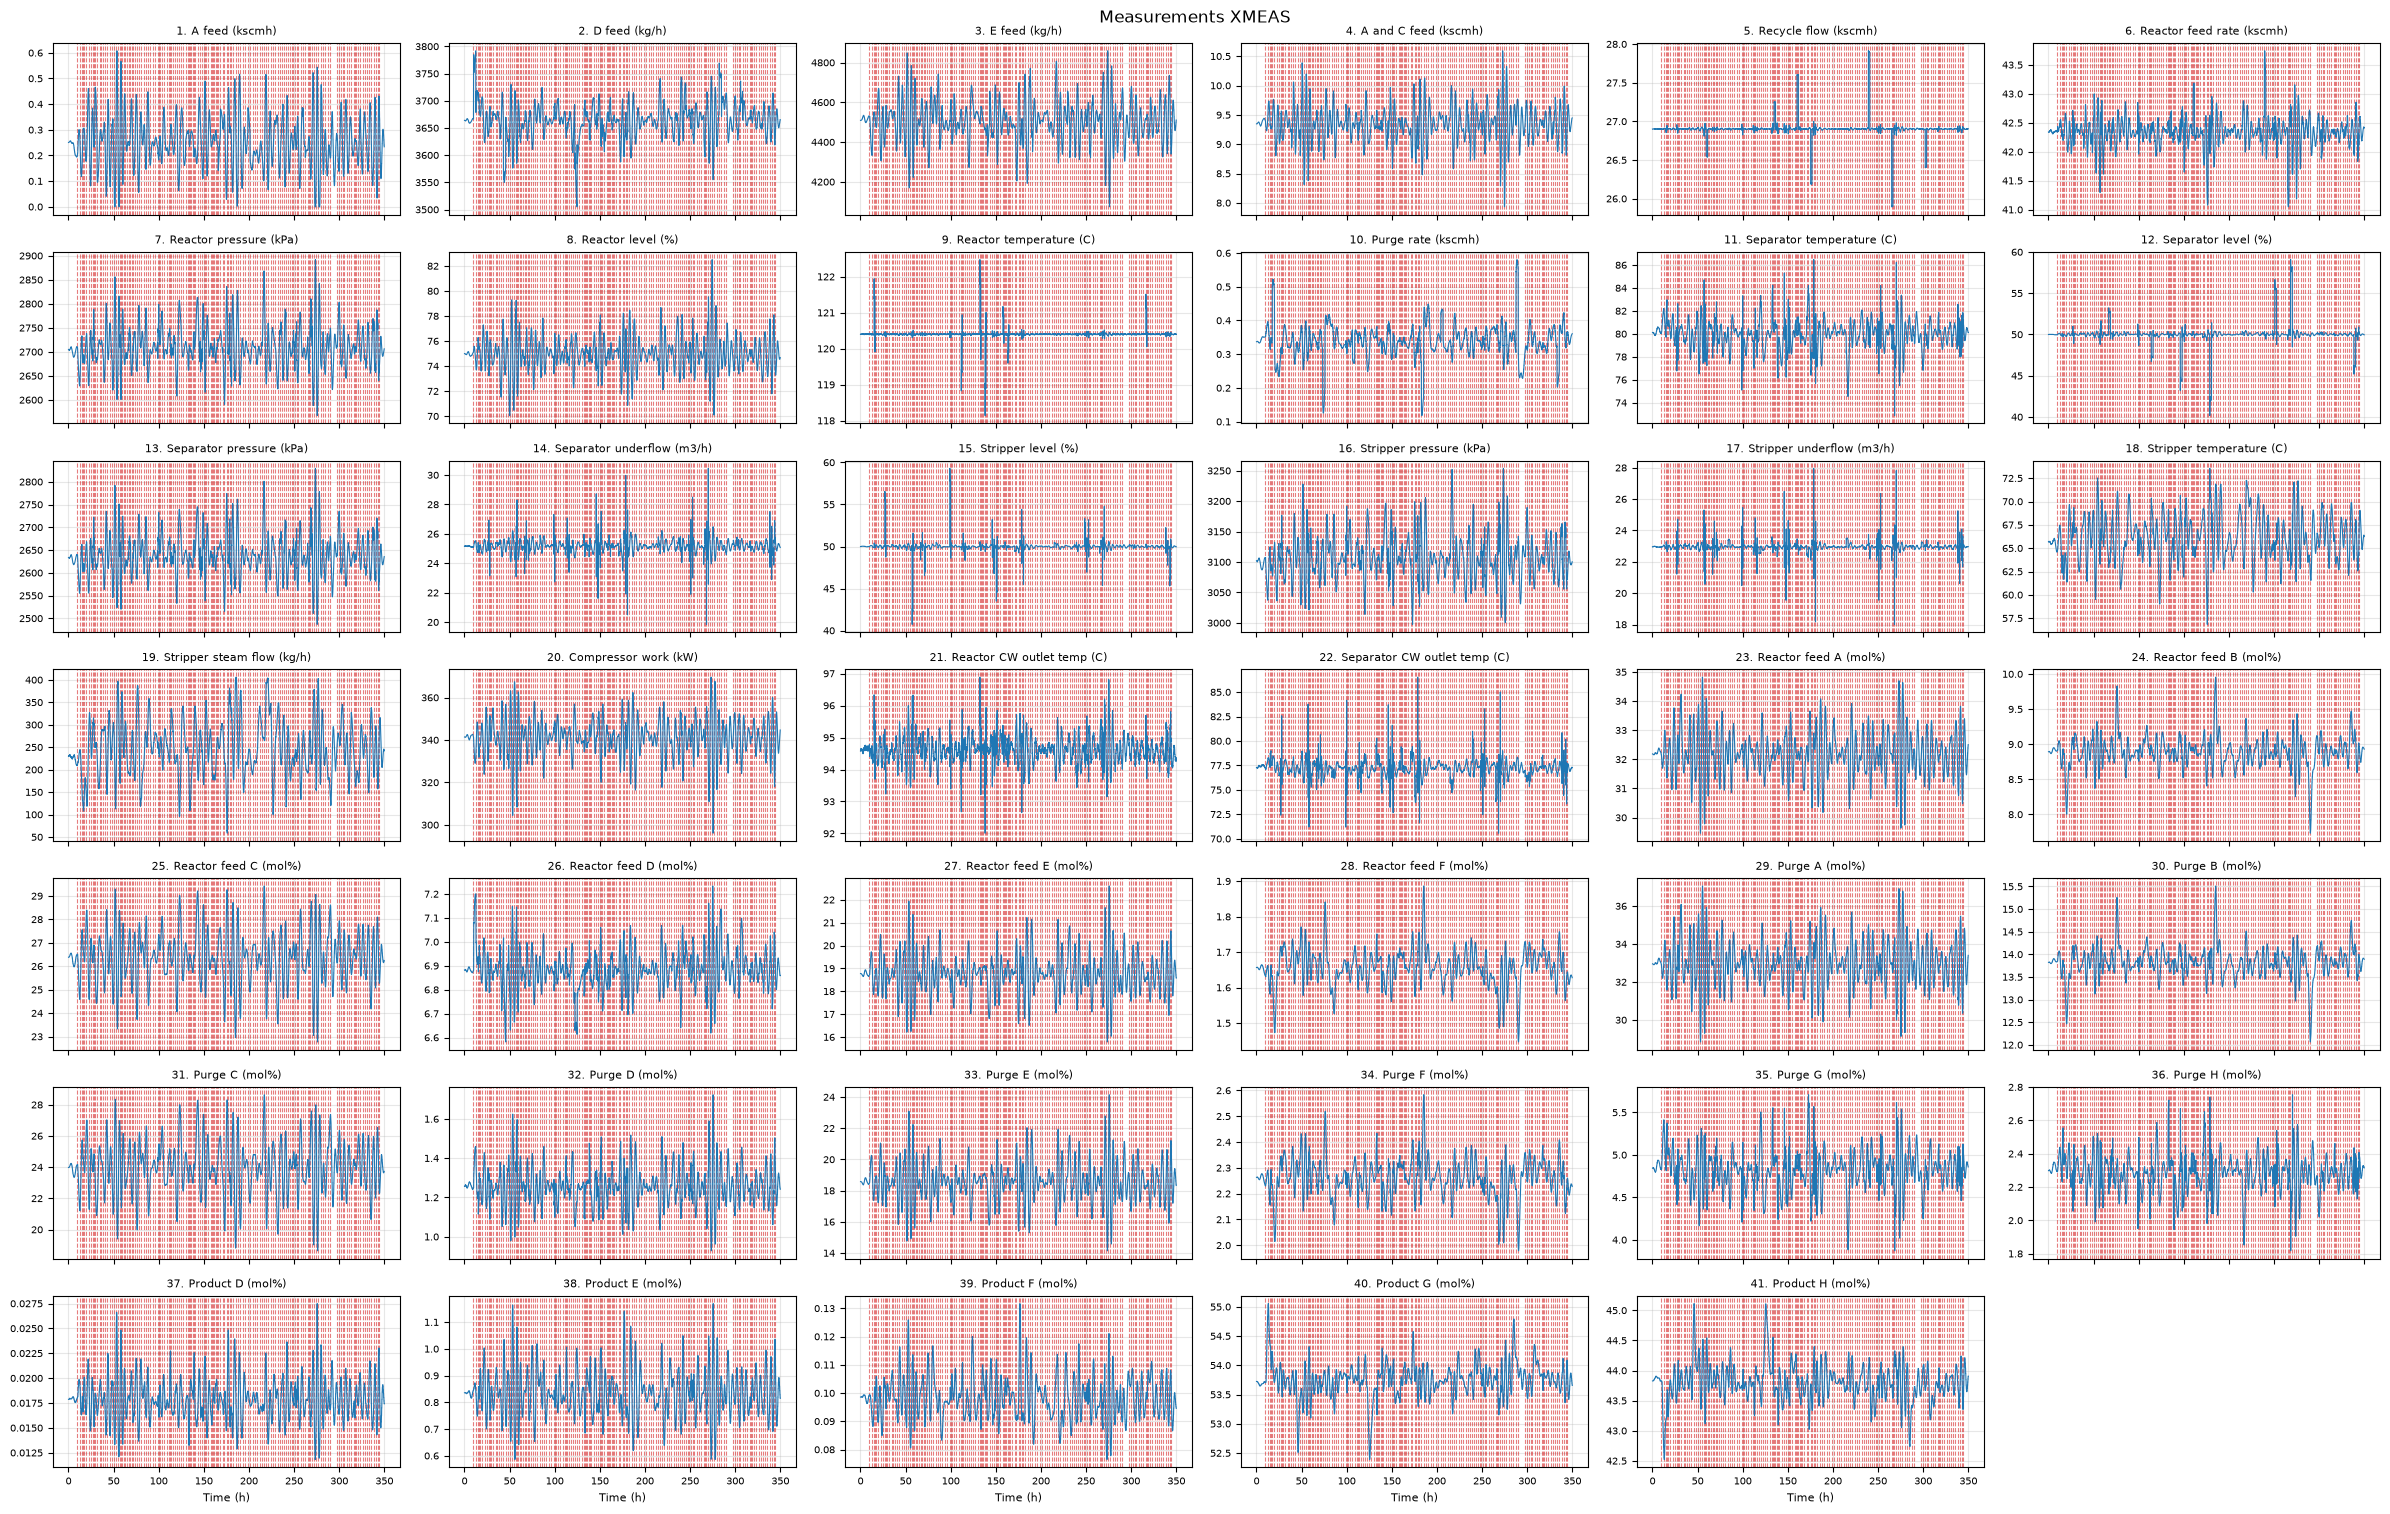

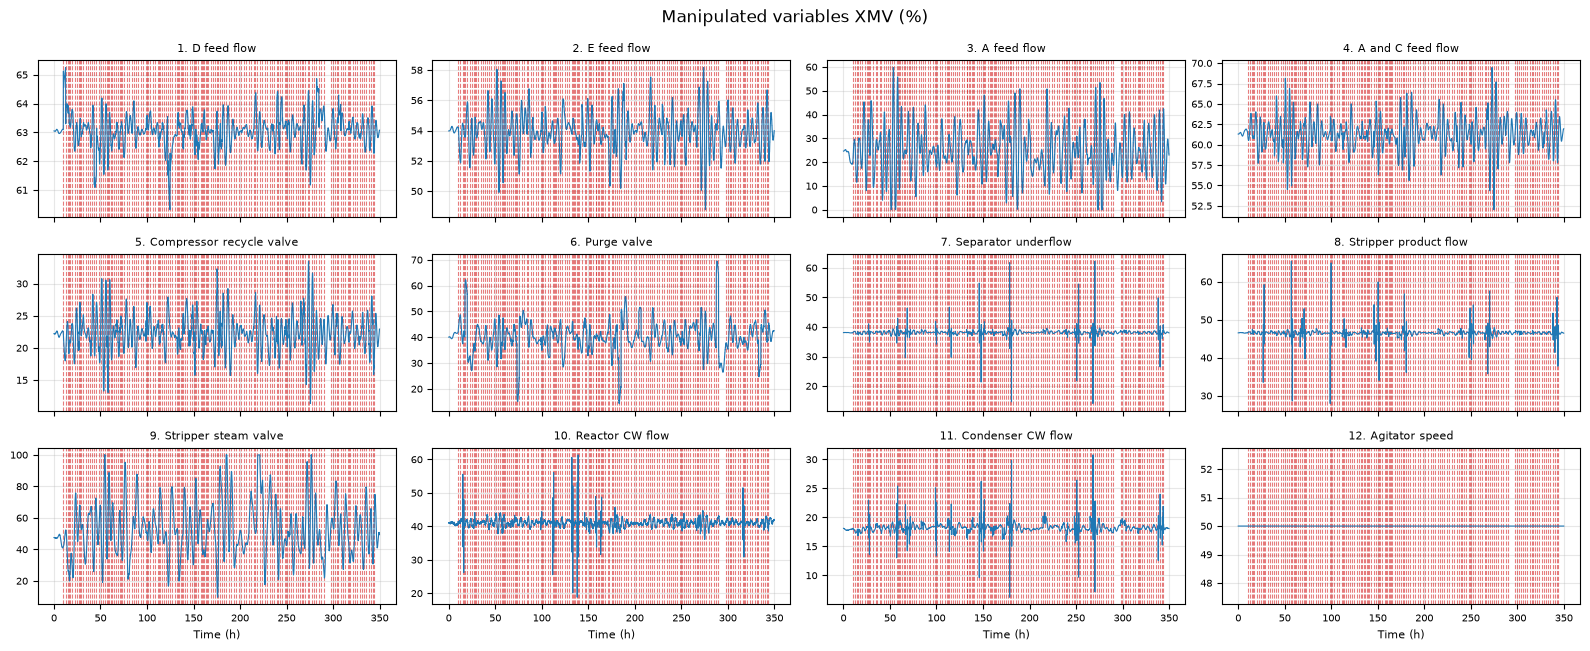

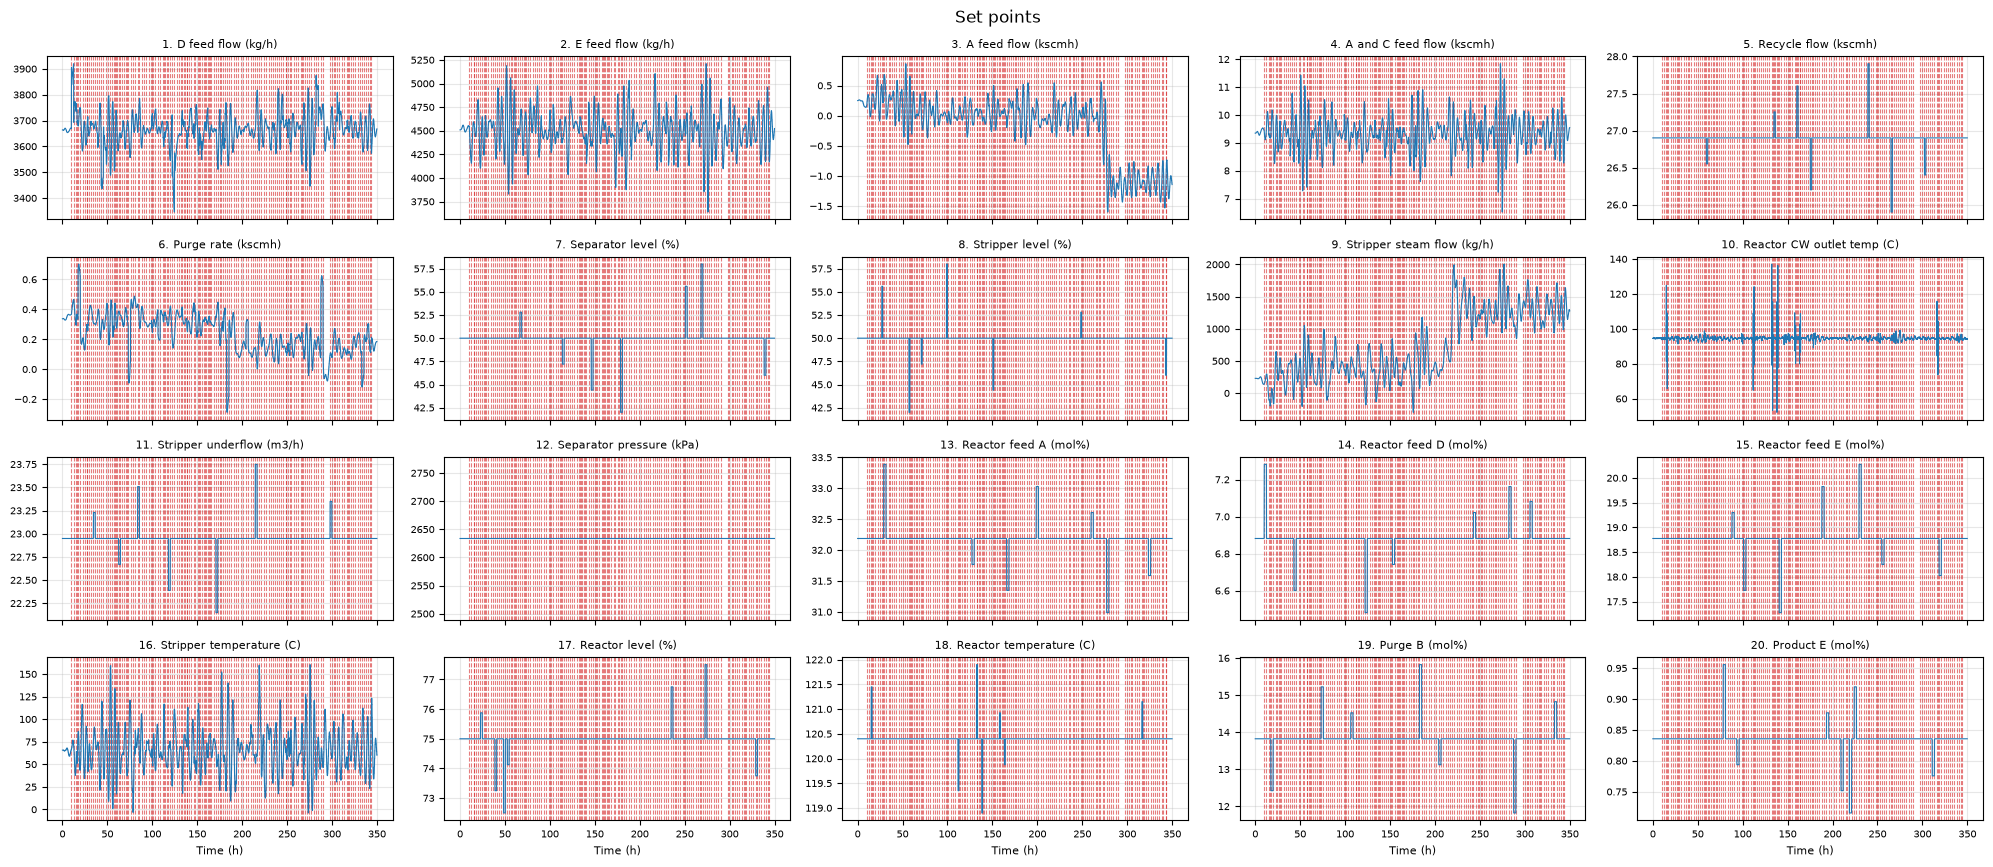

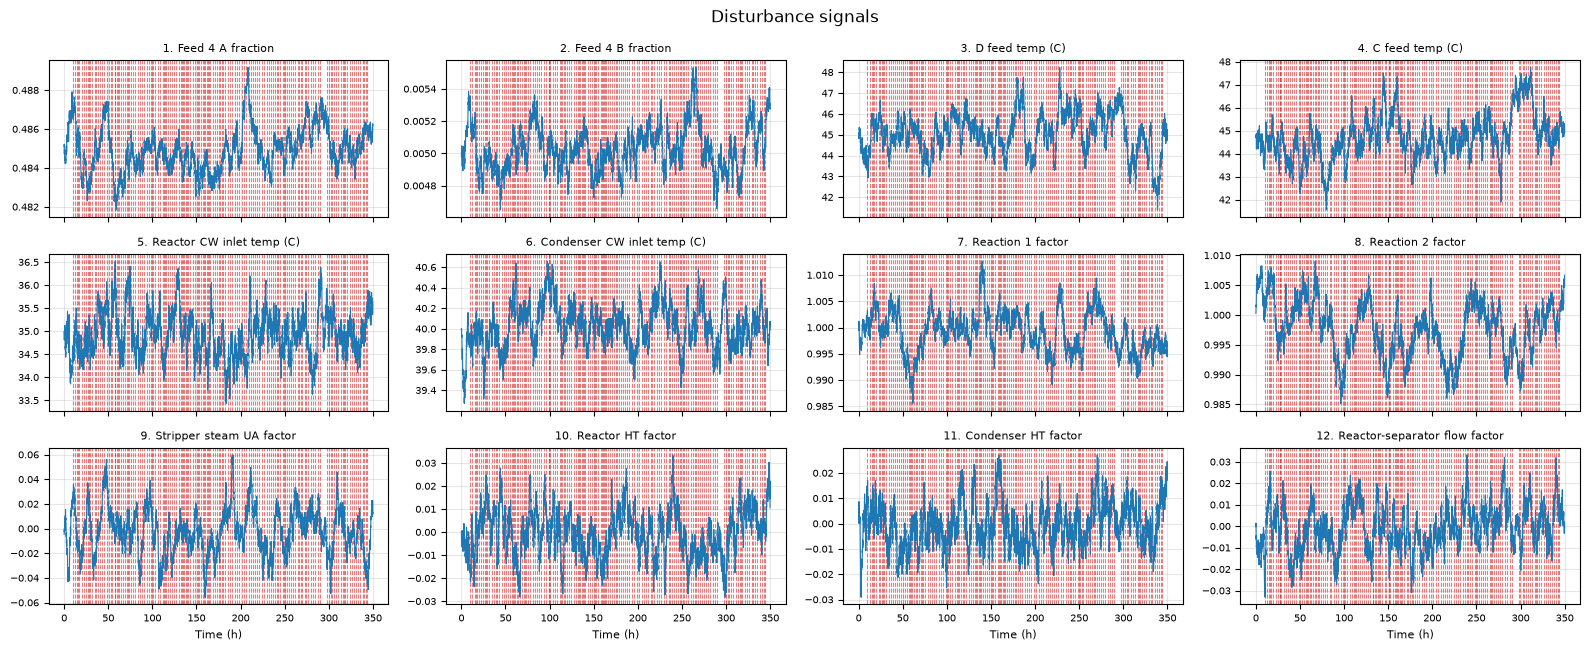

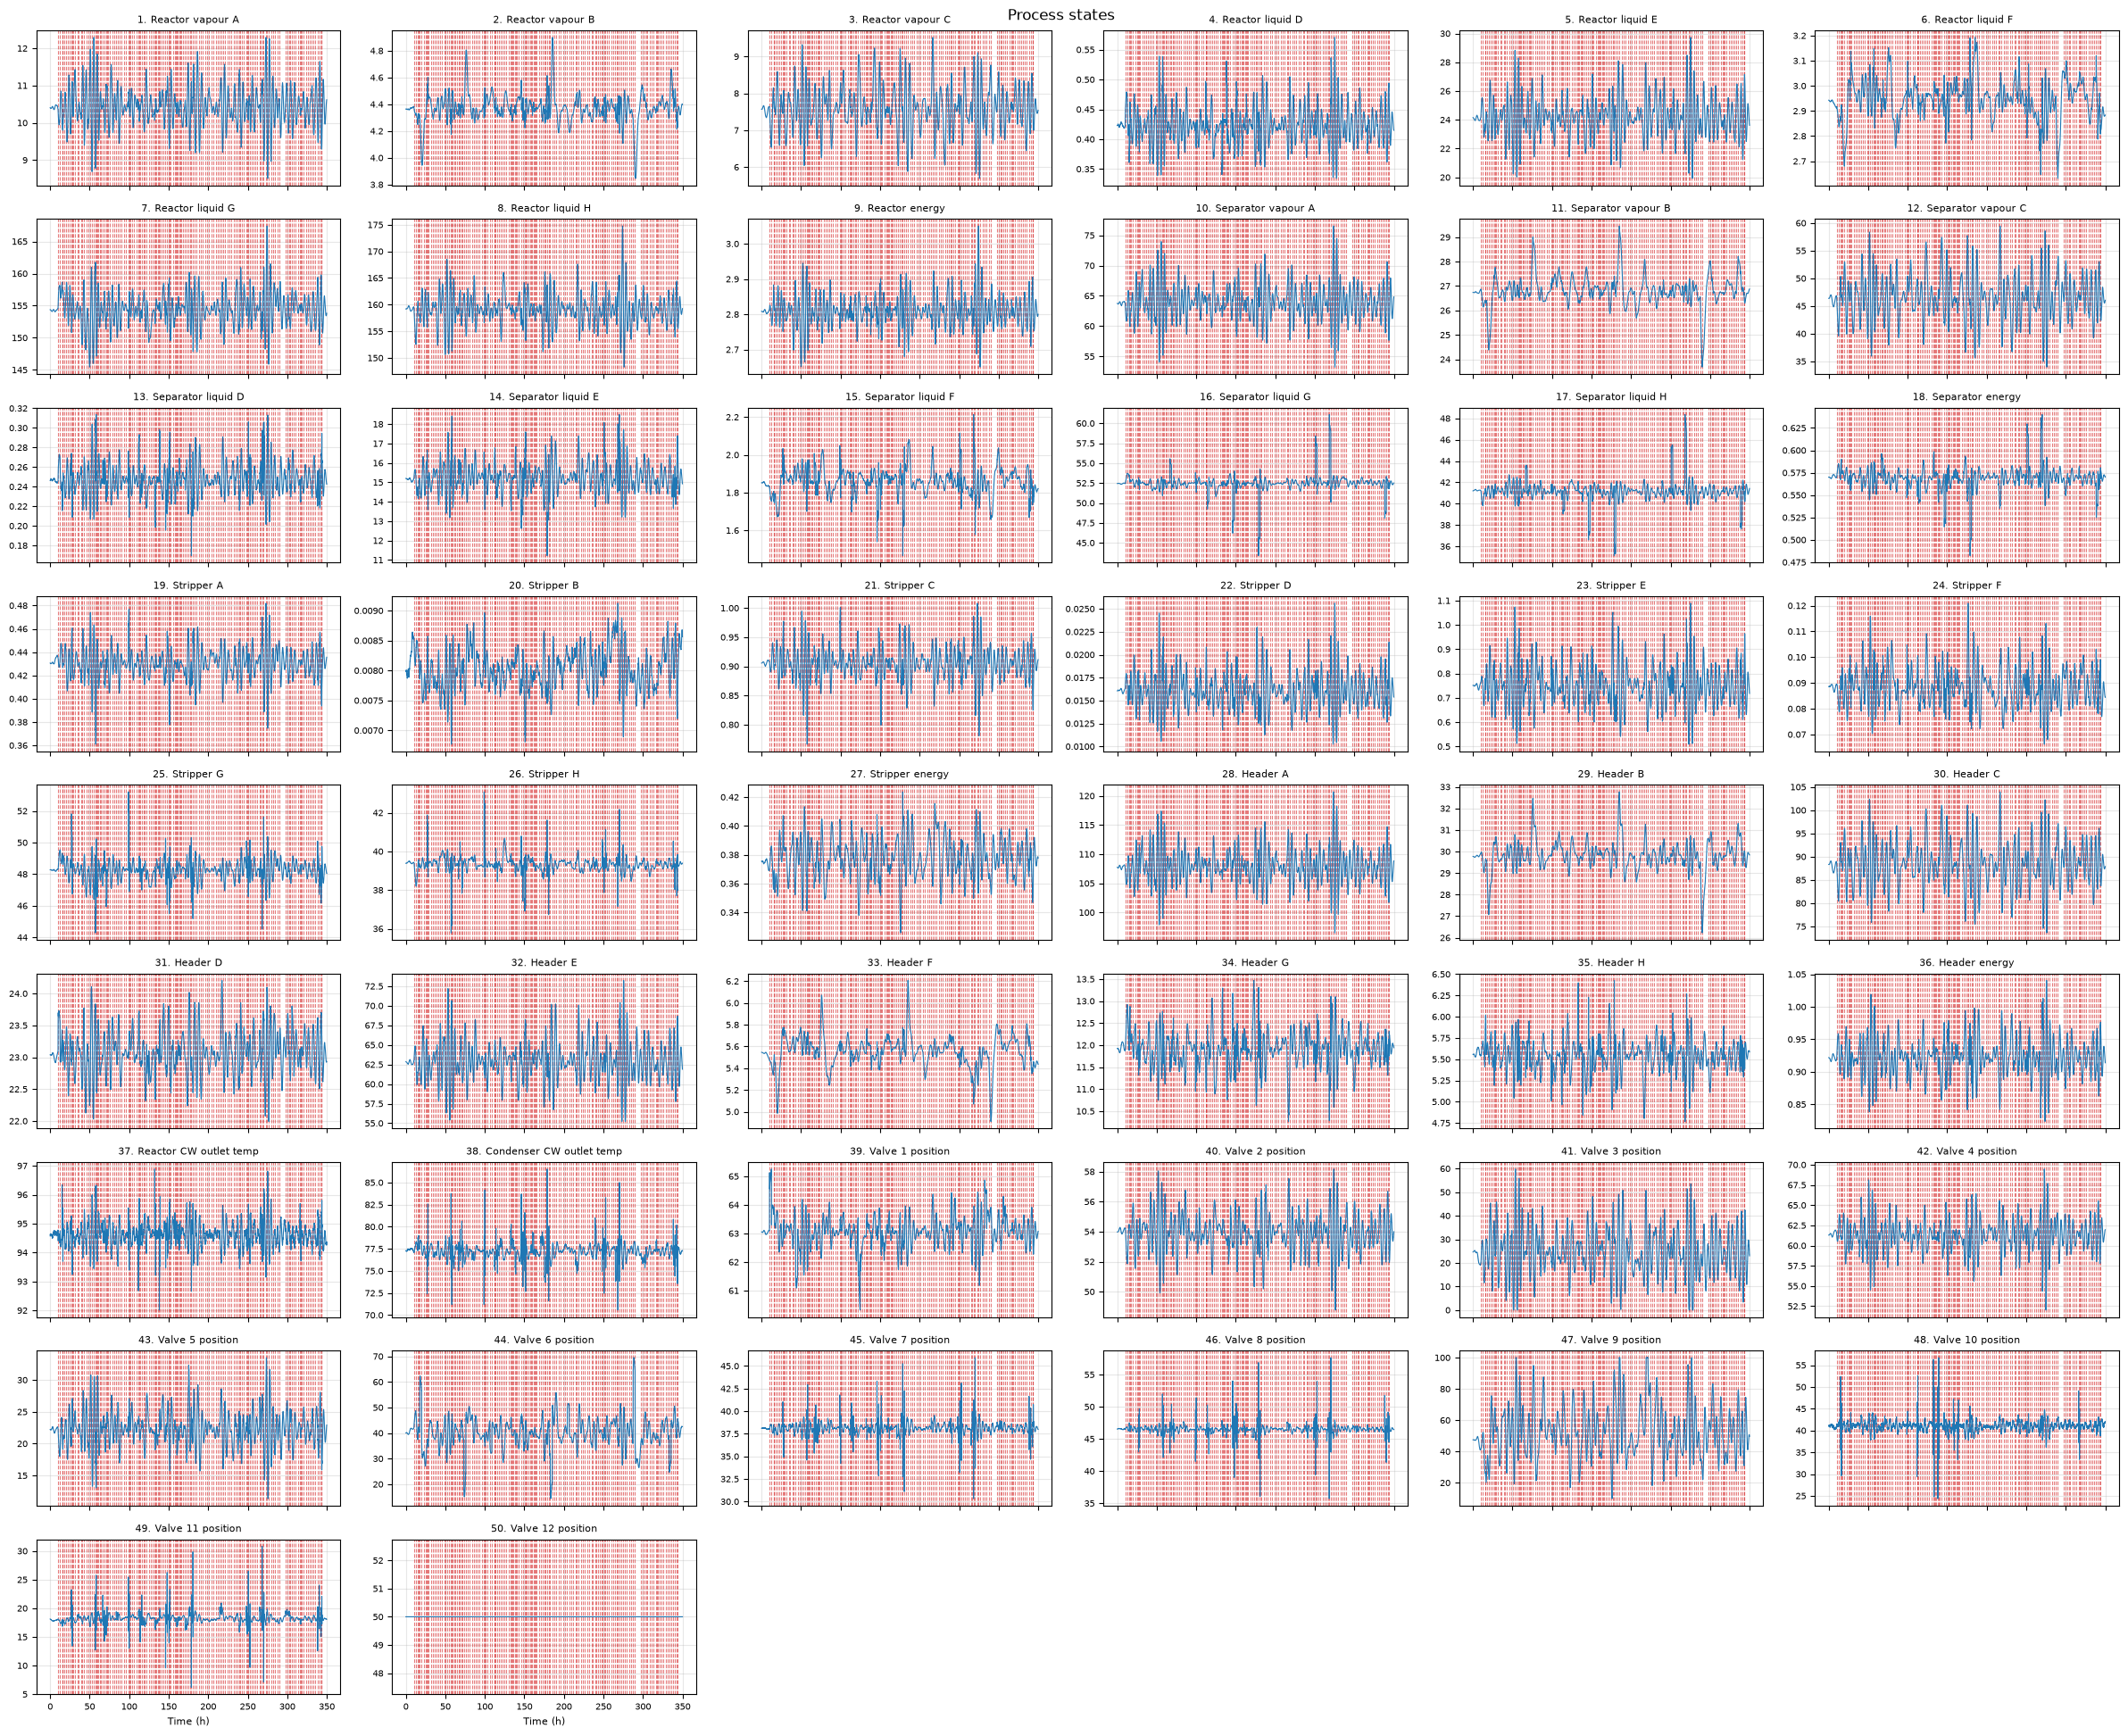

In [6]:
# Main

if __name__ == "__main__":
    out = simulate(CONFIG)
    print(out["xmeas"].shape, out["xmv"].shape)
    plot_results(out, CONFIG["setpoint_schedule"])

In [7]:
# Save results
import json
import h5py

def save_results(out, path="tep_sp_spaced_6min.h5", config=None):
    cfg = {**CONFIG, **(config or {})}
    names = {"xmeas": XMEAS_NAMES, "xmv": XMV_NAMES, "sp": SP_NAMES, "dist": DIST_NAMES,
             "y": STATE_NAMES}
    with h5py.File(path, "w") as f:
        f.create_dataset("t", data=out["t"])
        for key, cols in names.items():
            ds = f.create_dataset(key, data=out[key], compression="gzip")
            ds.attrs["names"] = cols
        f.attrs["shutdown"] = out["shutdown"]
        f.attrs["config"] = json.dumps(cfg)

FILE_NAMES = {"spaced": "tep_sp_spaced_6min", "clean": "tep_sp_clean", "ramp_dist": "tep_sp_ramp_dist"}
DATA_FILE = FILE_NAMES[DATASET] + ("_noisy" if NOISE else "") + ".h5"
save_results(out, DATA_FILE, CONFIG)
print(f"saved {DATA_FILE}")

In [8]:
# Load results
def load_results(path="tep_sp_spaced_6min.h5"):
    with h5py.File(path, "r") as f:
        out = {key: f[key][()] for key in f}
        names = {key: [n.decode() if isinstance(n, bytes) else str(n) for n in f[key].attrs["names"]]
                 for key in f if "names" in f[key].attrs}
        out["shutdown"] = bool(f.attrs["shutdown"])
        config = json.loads(f.attrs["config"])
    config["setpoints"] = {int(k): v for k, v in config["setpoints"].items()}
    return out, names, config

out, names, config = load_results(DATA_FILE)

t     = out["t"] / 3600     # time (h)
xmeas = out["xmeas"]        # (n, 41) measurements
xmv   = out["xmv"]          # (n, 12) manipulated variables
sp    = out["sp"]           # (n, 20) set points
dist  = out["dist"]         # (n, 12) disturbance signals
y     = out["y"]            # (n, 50) process states